# Final-sprint ladder-alignment research

**Evidence period: September 29–30, 2026. Publication correction: October 6, 2026.**

This notebook summarizes recorded AWS return-bundle aggregates. The main finding is a validation correction: the older opponent panel had saturated and overstated performance against recent ladder opponents. These are historical results, not a fresh competitive run.

The October publication repair re-executes the source and corrects stale chart outputs. The rescue chart includes only the three policies with recorded paired counts; missing counts are not inferred. The bar chart shows only reported game-count fields (zero also denotes an absent count); it is not a deduplicated cumulative game ledger. The 94 attempted games in the transport failure are excluded from completed-game counts.


In [1]:
import io
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from IPython.display import display

root = Path.cwd()
if not (root / "reports").is_dir():
    root = root.parent
report = json.loads((root / "reports" / "final_sprint_2026-09-30.json").read_text())


def show_with_static(figure, static_figure):
    stream = io.StringIO()
    static_figure.savefig(stream, format="svg", metadata={"Date": None}, bbox_inches="tight")
    plt.close(static_figure)
    display(
        {
            "application/vnd.plotly.v1+json": json.loads(figure.to_json()),
            "image/svg+xml": stream.getvalue(),
        },
        raw=True,
    )


rows = []
for name, item in report["milestones"].items():
    rows.append(
        {
            "milestone": name,
            "status": item.get("status"),
            "decision": item.get("decision") or item.get("scientific_decision"),
            "official_engine_games": item.get(
                "new_official_engine_games", item.get("branch_and_calibration_games", 0)
            ),
        }
    )
df = pd.DataFrame(rows)
display(df)

,milestone,status,decision,official_engine_games
0,late_layer_ablation,COMPLETED,REJECTED_SCREEN,234
1,onpolicy_population,COMPLETED,TRAINING_REJECTED,448
2,frontier_routes,COMPLETED,SCREEN_REJECTED,428
3,public_adaptive_frontier,COMPLETED,SCREEN_REJECTED,300
4,ladder_alignment,COMPLETED,NO_FIXED_POLICY_IMPROVEMENT,0
5,boundary_selector,COMPLETED,INNER_VALIDATION_REJECTED,1084
6,boundary_rule_cv,COMPLETED,ROLLING_CV_REJECTED,0
7,native_harvest_transport_failure,FAILED,NaN,0


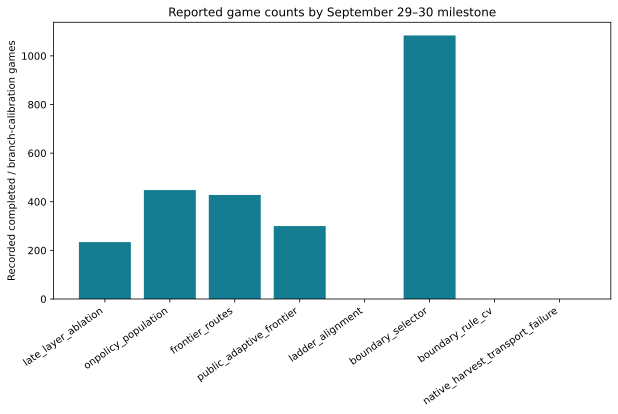

In [2]:
fig = px.bar(
    df,
    x="milestone",
    y="official_engine_games",
    hover_data=["status", "decision"],
    title="Reported game counts by September 29–30 milestone",
)
fig.update_layout(width=1000, height=500, xaxis_tickangle=-35)
static, axis = plt.subplots(figsize=(10, 5))
axis.bar(df["milestone"], df["official_engine_games"], color="#147D92")
axis.set_title("Reported game counts by September 29–30 milestone")
axis.set_ylabel("Recorded completed / branch-calibration games")
axis.tick_params(axis="x", labelrotation=35)
for label in axis.get_xticklabels():
    label.set_ha("right")
show_with_static(fig, static)

## Ladder-alignment correction

The replay-aligned validator requires exact terminal reward parity on the keeper before a counterfactual policy is scored. On the 48 recent keeper episodes used in the sprint, the keeper had **18 wins, 10 ties, and 20 losses (47.9% win/tie score)**. The older 24-episode development slice was **9 wins, 4 ties, and 11 losses (45.8%)**.

That result explained the mismatch between near-perfect performance on the old local panel and much weaker live rating.

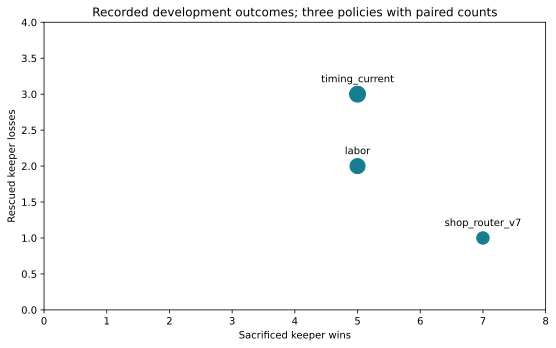

In [3]:
development = report["milestones"]["ladder_alignment"]["development"]
plot = pd.DataFrame(
    [
        {
            "policy": name,
            "score": values["score_rate"],
            "rescues": values["rescued_keeper_losses"],
            "sacrifices": values["sacrificed_keeper_wins"],
        }
        for name, values in development.items()
        if "rescued_keeper_losses" in values and "sacrificed_keeper_wins" in values
    ]
)
fig2 = px.scatter(
    plot,
    x="sacrifices",
    y="rescues",
    size="score",
    text="policy",
    title="Recorded development outcomes: rescues and sacrificed keeper wins",
)
fig2.update_traces(textposition="top center")
fig2.update_layout(width=900, height=520)
static, axis = plt.subplots(figsize=(9, 5.2))
axis.scatter(plot["sacrifices"], plot["rescues"], s=80 + 600 * plot["score"], color="#147D92")
for row in plot.itertuples():
    axis.annotate(
        row.policy,
        (row.sacrifices, row.rescues),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
    )
axis.set(xlim=(0, 8), ylim=(0, 4), xlabel="Sacrificed keeper wins", ylabel="Rescued keeper losses")
axis.set_title("Recorded development outcomes; three policies with paired counts")
show_with_static(fig2, static)

## Interpretation

Fixed replacement policies were globally worse than the keeper, although some rescued individual losses. The 1,084 branch-and-calibration games provided hindsight rescue opportunities, but the learned selector and subsequent rolling-origin rule search failed forward validation.

The source report gives a score for `v38_smarter_feed` but no paired rescue or sacrifice counts. It is deliberately omitted from that scatter chart.

As of the September 30 evidence cutoff, the next registered direction was native harvest/service recovery. Its first attempt failed in post-terminal diagnostics transport. The repair artifact was prepared, but no completed recovery experiment or improved agent score is established by this notebook.
